# E3. Baselines

All the baselines use the same folds as E1 (`Experiments/phenotypes/results/clinical/cross_validation/folds.csv`), with and without the context attributes:
- Antibiogram by unit: the score of an instance is the resistance rate of its unit in the training data.
- Top-k subgroups (k = 10) with the highest WRAcc among the candidate subgroups (as VLSD top-k), used as an unordered rule set: the score is the highest precision of the subgroups that cover the instance (default: base rate).
- Decision tree (maximum depth 4), logistic regression and gradient boosting (black-box reference, with SHAP).

Outputs: `results/tables/` and `results/figures/`.

In [1]:
import sys
sys.path.insert(0, "..")
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from scipy.stats import friedmanchisquare

In [2]:
view = "clinical"
df = utils.read_mining_view(view)
# Best hyperparameters of each configuration (Experiments/phenotypes/results/clinical/best_models.csv).
best_models = pd.read_csv(utils.best_models_path(view)).set_index("configuration")

def best_subgroup_lists(configuration):
    # Output file of DSLM (subgroups library) with the best hyperparameters.
    return utils.read_subgroup_lists(utils.best_subgroup_lists_path(view, best_models, configuration))

TABLES_PATH = utils.results_path("E3-baselines", "tables")
FIGURES_PATH = utils.results_path("E3-baselines", "figures")

cv_path = utils.cross_validation_path(view)
folds = pd.read_csv(cv_path / "folds.csv")["fold"]
predictions = pd.read_csv(cv_path / "predictions.csv")
y = utils.get_target_mask(df).astype(int)
X_with_context = pd.get_dummies(df.drop(columns=[utils.TARGET[0]]), dtype=int)
X_without_context = pd.get_dummies(df.drop(columns=[utils.TARGET[0]] + utils.CONTEXT_ATTRIBUTES), dtype=int)

In [3]:
def topk_scores(candidates_file_path, train, test, k=10):
    candidates = []
    with open(candidates_file_path) as input_file:
        for line in input_file:
            parts = line.rstrip("\n").split(" ; ")
            tp, fp = parts[1].count("1"), parts[2].count("1")
            candidates.append((utils.str_to_description(parts[0].split(", Target:")[0]), tp, fp))
    N, TP = len(train), utils.get_target_mask(train).sum()
    candidates = sorted(candidates, key=lambda c : ((c[1] + c[2]) / N) * (c[1] / (c[1] + c[2]) - TP / N), reverse=True)[:k]
    scores = np.full(len(test), (TP + 1) / (N + 2))
    best = np.zeros(len(test))
    for description, tp, fp in candidates:
        covered = utils.covers(test, description)
        best[covered] = np.maximum(best[covered], (tp + 1) / (tp + fp + 2))
    return np.where(best > 0, best, scores)

# 1. Cross-validation of the baselines

Note: the top-10 candidates by WRAcc can be the same with and without context (all of them are variations of the vancomycin attributes). This redundancy of the top-k approach is the motivation of the diverse subgroup lists.

In [4]:
models = {
    "decision_tree" : lambda : DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=utils.RANDOM_SEED),
    "logistic_regression" : lambda : LogisticRegression(max_iter=2000),
    "gradient_boosting" : lambda : GradientBoostingClassifier(random_state=utils.RANDOM_SEED),
}
rows = []
for fold in range(folds.max() + 1):
    train_mask, test_mask = (folds != fold).values, (folds == fold).values
    train, test = df[train_mask].reset_index(drop=True), df[test_mask].reset_index(drop=True)
    scores = {}
    unit_rates = train.assign(r=utils.get_target_mask(train)).groupby(utils.UNIT_ATTRIBUTE)["r"].mean()
    scores["antibiogram_by_unit"] = test[utils.UNIT_ATTRIBUTE].map(unit_rates).values
    for context, X in [("with_context", X_with_context), ("without_context", X_without_context)]:
        for name, model in models.items():
            scores[name + "_" + context] = model().fit(X[train_mask], y[train_mask]).predict_proba(X[test_mask])[:, 1]
        scores["topk_subgroups_" + context] = topk_scores(cv_path / ("fold_" + str(fold)) / (context + "_candidates.txt"), train, test)
    fold_predictions = predictions[predictions["fold"] == fold].set_index("row").loc[np.where(test_mask)[0]]
    for name in ["without_context", "with_context", "per_unit"]:
        scores["EDSLM_" + name] = fold_predictions["score_" + name].values
    for name, score in scores.items():
        rows.append({"fold" : fold, "model" : name, "auc_roc" : roc_auc_score(y[test_mask], score), "auc_pr" : average_precision_score(y[test_mask], score)})
fold_metrics = pd.DataFrame(rows)
fold_metrics.to_csv(TABLES_PATH / "baselines_auc_by_fold.csv", index=False)
summary = fold_metrics.groupby("model")[["auc_roc", "auc_pr"]].agg(["mean", "std"]).sort_values(("auc_roc", "mean"), ascending=False)
summary.to_csv(TABLES_PATH / "baselines_auc_summary.csv")
summary.round(3)

auc_roc        auc_pr       
                                       mean    std   mean    std
model                                                           
gradient_boosting_with_context        0.806  0.028  0.655  0.044
logistic_regression_with_context      0.804  0.029  0.662  0.049
logistic_regression_without_context   0.780  0.029  0.619  0.046
decision_tree_with_context            0.779  0.027  0.591  0.048
gradient_boosting_without_context     0.779  0.028  0.615  0.033
decision_tree_without_context         0.776  0.034  0.590  0.042
EDSLM_without_context                 0.733  0.032  0.566  0.041
EDSLM_with_context                    0.721  0.038  0.574  0.047
EDSLM_per_unit                        0.718  0.051  0.557  0.058
topk_subgroups_with_context           0.707  0.019  0.485  0.015
topk_subgroups_without_context        0.707  0.019  0.485  0.015
antibiogram_by_unit                   0.605  0.045  0.398  0.041

In [5]:
pivot = fold_metrics.pivot(index="fold", columns="model", values="auc_roc")
statistic, p_value = friedmanchisquare(*[pivot[c] for c in pivot.columns])
print("Friedman test (AUC-ROC, all models): statistic = " + str(round(statistic, 2)) + ", p-value = " + "{:.2e}".format(p_value))
pd.DataFrame([{"test" : "friedman", "metric" : "auc_roc", "statistic" : statistic, "p_value" : p_value}]).to_csv(TABLES_PATH / "friedman_test.csv", index=False)

Friedman test (AUC-ROC, all models): statistic = 95.07, p-value = 1.68e-15


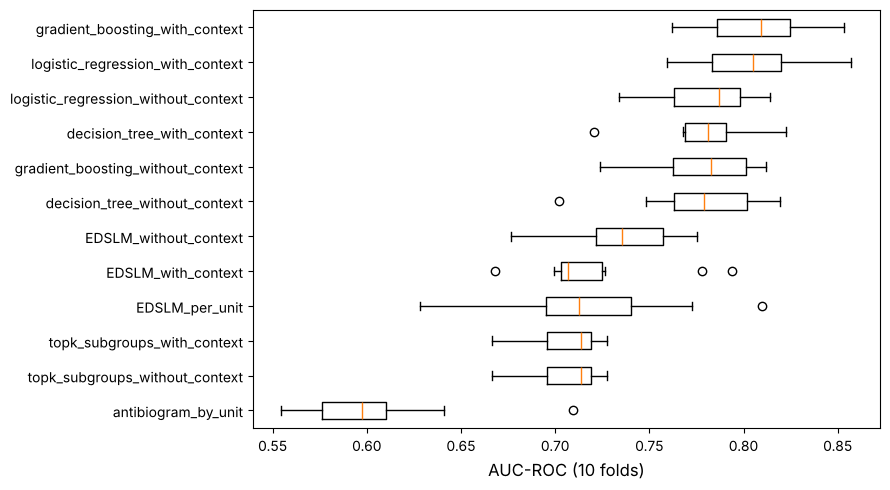

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
order = summary.index.tolist()[::-1]
ax.boxplot([pivot[m] for m in order], orientation="horizontal", tick_labels=order)
ax.set_xlabel("AUC-ROC (10 folds)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "baselines_auc.pdf")
plt.show()

# 2. Interpretable baseline: decision tree with context (full dataset)

In [7]:
tree = models["decision_tree"]().fit(X_with_context, y)
tree_text = export_text(tree, feature_names=list(X_with_context.columns), max_depth=4)
(TABLES_PATH / "decision_tree_with_context.txt").write_text(tree_text)
print(tree_text)

|--- treated_with_vancomycin_in_the_current_admission_before_culture_yes <= 0.50
|   |--- treated_with_vancomycin_in_previous_admissions_yes <= 0.50
|   |   |--- hours_from_admission_to_first_icu_83<x <= 0.50
|   |   |   |--- culture_specimen_type_URINE <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- culture_specimen_type_URINE >  0.50
|   |   |   |   |--- class: 0
|   |   |--- hours_from_admission_to_first_icu_83<x >  0.50
|   |   |   |--- icu_when_culture_SICU <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- icu_when_culture_SICU >  0.50
|   |   |   |   |--- class: 0
|   |--- treated_with_vancomycin_in_previous_admissions_yes >  0.50
|   |   |--- admission_location_EMERGENCY_ROOM <= 0.50
|   |   |   |--- catheter_in_previous_admissions_yes <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- catheter_in_previous_admissions_yes >  0.50
|   |   |   |   |--- class: 1
|   |   |--- admission_location_EMERGENCY_ROOM >  0.50
|   |   |   |--- previous_exposure_to_b_lactam_no <

# 3. Black-box reference: gradient boosting with context + SHAP (full dataset)

In [8]:
import shap
gradient_boosting = models["gradient_boosting"]().fit(X_with_context, y)
shap_values = shap.TreeExplainer(gradient_boosting).shap_values(X_with_context)
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_with_context.columns)
# Aggregation of the one-hot columns into the original attributes.
attribute_of = {column : next(a for a in sorted(df.columns, key=len, reverse=True) if column.startswith(a + "_")) for column in X_with_context.columns}
importance_by_attribute = importance.groupby(attribute_of).sum().sort_values(ascending=False)
importance.to_frame("mean_abs_shap").to_csv(TABLES_PATH / "shap_importance_by_column.csv")
shap_table = importance_by_attribute.to_frame("mean_abs_shap").assign(context=lambda t : t.index.isin(utils.CONTEXT_ATTRIBUTES))
shap_table.to_csv(TABLES_PATH / "shap_importance_by_attribute.csv")
shap_table.round(4)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,mean_abs_shap,context
treated_with_vancomycin_in_the_current_admission_before_culture,0.7677,False
service_when_culture,0.6362,True
treated_with_vancomycin_in_previous_admissions,0.2753,False
admission_location,0.2249,False
culture_specimen_type,0.2075,False
hours_from_admission_to_first_icu,0.2033,True
icu_when_culture,0.1288,True
patient_gender,0.0545,False
readmission,0.0516,False
previous_exposure_to_third_generation_cephalosporins,0.0406,False


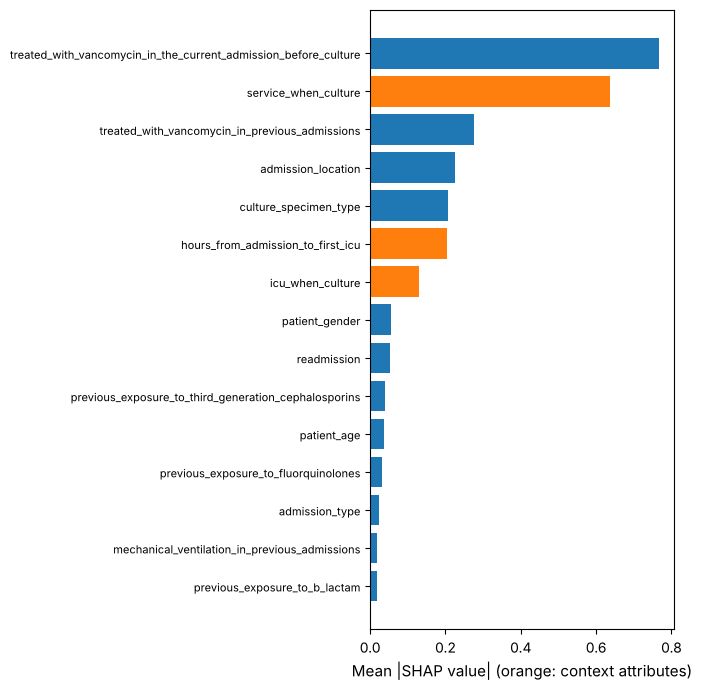

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
top = importance_by_attribute.head(15)[::-1]
ax.barh(top.index, top.values, color=["tab:orange" if a in utils.CONTEXT_ATTRIBUTES else "tab:blue" for a in top.index])
ax.set_xlabel("Mean |SHAP value| (orange: context attributes)", fontsize=11)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "shap_importance.pdf")
plt.show()